In [1]:
import os
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
GPU: Tesla T4


In [3]:
import os

print("Folders inside /content:")
print(os.listdir("/content"))

Folders inside /content:
['.config', 'sample_data']


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [19]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Rice_Disease_Project"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project folder created:", PROJECT_DIR)
print("Exists:", os.path.exists(PROJECT_DIR))

Project folder created: /content/drive/MyDrive/Rice_Disease_Project
Exists: True


In [20]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Rice_Disease_Project"

folders = [
    "dataset",
    "dataset/raw",
    "dataset/processed",
    "models",
    "results",
    "plots"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project structure created successfully!\n")

for folder in folders:
    print("✔", folder)

Project structure created successfully!

✔ dataset
✔ dataset/raw
✔ dataset/processed
✔ models
✔ results
✔ plots


In [2]:
from google.colab import files

uploaded = files.upload()

Saving archive (2).zip to archive (2).zip


In [3]:
import zipfile
import os

ZIP_PATH = "/content/archive (2).zip"
RAW_DIR = "/content/drive/MyDrive/Rice_Disease_Project/dataset/raw"

os.makedirs(RAW_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(RAW_DIR)

print("Dataset extracted successfully!")
print("Location:", RAW_DIR)
print("Files extracted:", len(os.listdir(RAW_DIR)))

Dataset extracted successfully!
Location: /content/drive/MyDrive/Rice_Disease_Project/dataset/raw
Files extracted: 1


In [4]:
import os

RAW_DIR = "/content/drive/MyDrive/Rice_Disease_Project/dataset/raw"

print("Contents of raw folder:\n")

for root, dirs, files in os.walk(RAW_DIR):
    level = root.replace(RAW_DIR, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    if level >= 2:
        dirs[:] = []

Contents of raw folder:

raw/
    rice-leaf-desease/
        Leaf smut/
        Health/
        Bacterial leaf blight/
        Brown spot/


In [5]:
import os

DATASET_DIR = "/content/drive/MyDrive/Rice_Disease_Project/dataset/raw/rice-leaf-desease"

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

total_images = 0

print("IMAGE COUNT PER CLASS\n")
print("-" * 40)

for class_name in sorted(os.listdir(DATASET_DIR)):
    class_path = os.path.join(DATASET_DIR, class_name)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(image_extensions)
        ]

        count = len(images)
        total_images += count

        print(f"{class_name:25s}: {count}")

print("-" * 40)
print(f"TOTAL IMAGES             : {total_images}")

IMAGE COUNT PER CLASS

----------------------------------------
Bacterial leaf blight    : 4000
Brown spot               : 4000
Health                   : 4000
Leaf smut                : 4000
----------------------------------------
TOTAL IMAGES             : 16000


In [6]:
from PIL import Image
import os

DATASET_DIR = "/content/drive/MyDrive/Rice_Disease_Project/dataset/raw/rice-leaf-desease"

corrupted_images = []
total_checked = 0

for class_name in os.listdir(DATASET_DIR):
    class_path = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    for file_name in os.listdir(class_path):
        if file_name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            image_path = os.path.join(class_path, file_name)
            total_checked += 1

            try:
                with Image.open(image_path) as img:
                    img.verify()
            except Exception:
                corrupted_images.append(image_path)

print("Images checked:", total_checked)
print("Corrupted images:", len(corrupted_images))

if len(corrupted_images) == 0:
    print("All images are valid!")
else:
    print("\nCorrupted image paths:")
    for path in corrupted_images[:20]:
        print(path)

Images checked: 16000
Corrupted images: 0
All images are valid!


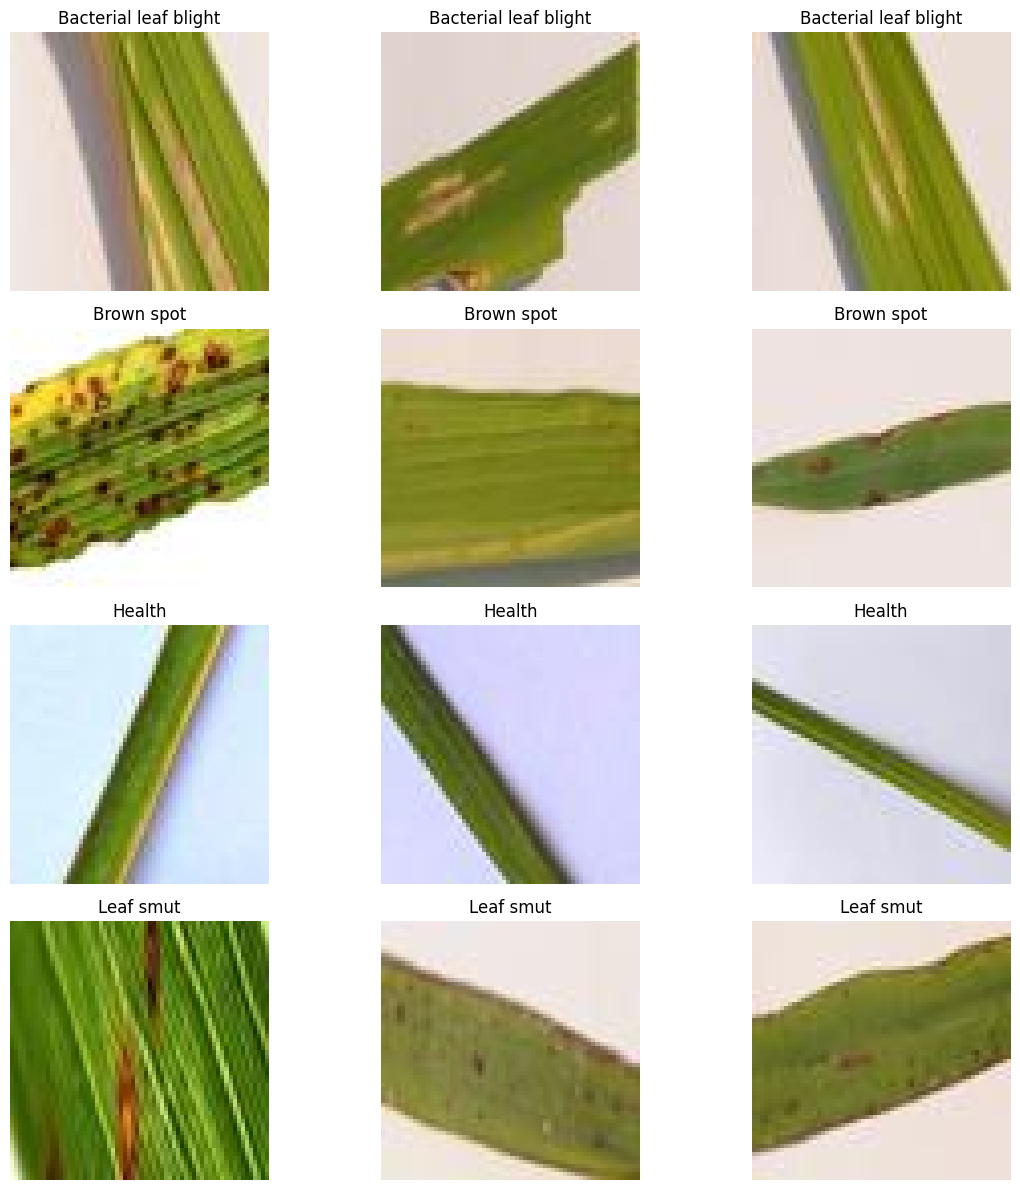

In [7]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

DATASET_DIR = "/content/drive/MyDrive/Rice_Disease_Project/dataset/raw/rice-leaf-desease"

classes = sorted(os.listdir(DATASET_DIR))

plt.figure(figsize=(12, 12))

for i, class_name in enumerate(classes):
    class_path = os.path.join(DATASET_DIR, class_name)

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    samples = random.sample(images, min(3, len(images)))

    for j, img_name in enumerate(samples):
        img_path = os.path.join(class_path, img_name)
        img = Image.open(img_path).convert("RGB")

        plt.subplot(4, 3, i * 3 + j + 1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(class_name)

plt.tight_layout()
plt.show()

In [8]:
import os
from PIL import Image
from collections import Counter

DATASET_DIR = "/content/drive/MyDrive/Rice_Disease_Project/dataset/raw/rice-leaf-desease"

dimension_counts = Counter()
image_modes = Counter()

for class_name in sorted(os.listdir(DATASET_DIR)):
    class_path = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    # Inspect a maximum of 100 images per class
    sample_images = images[:100]

    for file_name in sample_images:
        image_path = os.path.join(class_path, file_name)

        with Image.open(image_path) as img:
            dimension_counts[img.size] += 1
            image_modes[img.mode] += 1

print("Image dimensions (width, height):")
for dimension, count in dimension_counts.most_common(10):
    print(dimension, ":", count)

print("\nImage color modes:")
for mode, count in image_modes.items():
    print(mode, ":", count)

Image dimensions (width, height):
(64, 64) : 400

Image color modes:
RGB : 400


In [9]:
import os
from PIL import Image

RAW_DIR = "/content/drive/MyDrive/Rice_Disease_Project/dataset/raw/rice-leaf-desease"

corrupted_images = []
total_checked = 0

for class_name in os.listdir(RAW_DIR):
    class_path = os.path.join(RAW_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    for img_name in os.listdir(class_path):
        img_path = os.path.join(class_path, img_name)

        try:
            with Image.open(img_path) as img:
                img.verify()
            total_checked += 1

        except Exception:
            corrupted_images.append(img_path)

print("Total images checked:", total_checked)
print("Corrupted images:", len(corrupted_images))

if corrupted_images:
    print("\nCorrupted files:")
    for path in corrupted_images[:10]:
        print(path)
else:
    print("All images are valid! ✅")

Total images checked: 16000
Corrupted images: 0
All images are valid! ✅


In [10]:
import os

DATASET_DIR = "/content/drive/MyDrive/Rice_Disease_Project/dataset/raw/rice-leaf-desease"

print("Dataset path:", DATASET_DIR)
print("Exists:", os.path.exists(DATASET_DIR))
print("\nClasses:", os.listdir(DATASET_DIR))

Dataset path: /content/drive/MyDrive/Rice_Disease_Project/dataset/raw/rice-leaf-desease
Exists: True

Classes: ['Leaf smut', 'Health', 'Bacterial leaf blight', 'Brown spot']


In [11]:
import os

class_counts = {}

for class_name in os.listdir(DATASET_DIR):
    class_path = os.path.join(DATASET_DIR, class_name)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
        ]

        class_counts[class_name] = len(images)

print("DATASET DISTRIBUTION")
print("-" * 40)

for class_name, count in class_counts.items():
    print(f"{class_name:25s}: {count}")

print("-" * 40)
print("Total images:", sum(class_counts.values()))

DATASET DISTRIBUTION
----------------------------------------
Leaf smut                : 4000
Health                   : 4000
Bacterial leaf blight    : 4000
Brown spot               : 4000
----------------------------------------
Total images: 16000


In [12]:
from sklearn.model_selection import train_test_split
import os

image_paths = []
labels = []

for class_name in sorted(os.listdir(DATASET_DIR)):
    class_path = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    for file in os.listdir(class_path):
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            image_paths.append(os.path.join(class_path, file))
            labels.append(class_name)

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Second split: divide remaining 30% equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("DATA SPLIT SUMMARY")
print("-" * 40)
print("Training images  :", len(X_train))
print("Validation images :", len(X_val))
print("Testing images   :", len(X_test))
print("Total            :", len(X_train) + len(X_val) + len(X_test))

DATA SPLIT SUMMARY
----------------------------------------
Training images  : 11200
Validation images : 2400
Testing images   : 2400
Total            : 16000


In [13]:
from collections import Counter

print("TRAINING DISTRIBUTION")
print(Counter(y_train))

print("\nVALIDATION DISTRIBUTION")
print(Counter(y_val))

print("\nTEST DISTRIBUTION")
print(Counter(y_test))

TRAINING DISTRIBUTION
Counter({'Health': 2800, 'Bacterial leaf blight': 2800, 'Brown spot': 2800, 'Leaf smut': 2800})

VALIDATION DISTRIBUTION
Counter({'Bacterial leaf blight': 600, 'Health': 600, 'Brown spot': 600, 'Leaf smut': 600})

TEST DISTRIBUTION
Counter({'Brown spot': 600, 'Health': 600, 'Leaf smut': 600, 'Bacterial leaf blight': 600})


In [14]:
import torch
from torchvision import transforms

IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Preprocessing pipeline created successfully!")
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Training augmentation: Enabled")
print("Validation/Test augmentation: Disabled")

Preprocessing pipeline created successfully!
Image size: 224 x 224
Training augmentation: Enabled
Validation/Test augmentation: Disabled


In [15]:
from torch.utils.data import Dataset
from PIL import Image
import os

class RiceDiseaseDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

# Create datasets
train_dataset = RiceDiseaseDataset(
    X_train, y_train, train_transform
)

val_dataset = RiceDiseaseDataset(
    X_val, y_val, eval_transform
)

test_dataset = RiceDiseaseDataset(
    X_test, y_test, eval_transform
)

print("Datasets created successfully!")
print("-" * 40)
print("Training dataset   :", len(train_dataset))
print("Validation dataset :", len(val_dataset))
print("Testing dataset   :", len(test_dataset))

Datasets created successfully!
----------------------------------------
Training dataset   : 11200
Validation dataset : 2400
Testing dataset   : 2400


In [16]:
# Load one sample from the training dataset

image, label = train_dataset[0]

print("Image tensor shape:", image.shape)
print("Label:", label)
print("Image tensor type:", type(image))
print("Image dtype:", image.dtype)
print("Image min value:", image.min().item())
print("Image max value:", image.max().item())

Image tensor shape: torch.Size([3, 224, 224])
Label: Health
Image tensor type: <class 'torch.Tensor'>
Image dtype: torch.float32
Image min value: -1.9466564655303955
Image max value: 1.6639653444290161


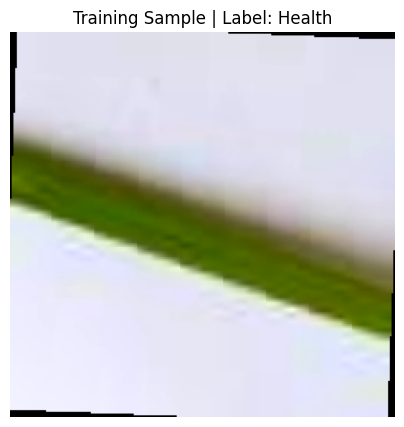

In [17]:
import matplotlib.pyplot as plt

image, label = train_dataset[0]

# Convert tensor back to display format
image_display = image.permute(1, 2, 0)

# Undo normalization for visualization
mean = torch.tensor([0.485, 0.456, 0.406])
std = torch.tensor([0.229, 0.224, 0.225])

image_display = image_display * std + mean
image_display = image_display.clamp(0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(image_display)
plt.title(f"Training Sample | Label: {label}")
plt.axis("off")
plt.show()

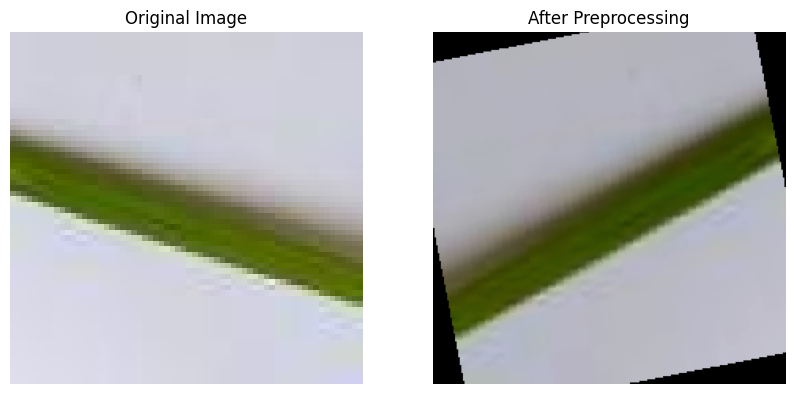

In [18]:
import matplotlib.pyplot as plt
from PIL import Image

sample_path = X_train[0]

original = Image.open(sample_path).convert("RGB")
transformed, label = train_dataset[0]

# Undo normalization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

transformed = transformed * std + mean
transformed = transformed.clamp(0, 1)
transformed = transformed.permute(1, 2, 0).numpy()

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(transformed)
plt.title("After Preprocessing")
plt.axis("off")

plt.show()

In [19]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch

BATCH_SIZE = 32

class RiceDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

# Create datasets
train_dataset = RiceDataset(X_train, y_train, train_transform)
val_dataset = RiceDataset(X_val, y_val, eval_transform)
test_dataset = RiceDataset(X_test, y_test, eval_transform)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully! ✅")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully! ✅
Training batches: 350
Validation batches: 75
Testing batches: 75


In [21]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch type:", type(labels))
print("Image data type:", images.dtype)
print("First 10 labels:", labels[:10])

print("\nNumber of images in batch:", len(images))

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch type: <class 'tuple'>
Image data type: torch.float32
First 10 labels: ('Leaf smut', 'Health', 'Leaf smut', 'Leaf smut', 'Brown spot', 'Leaf smut', 'Health', 'Brown spot', 'Leaf smut', 'Bacterial leaf blight')

Number of images in batch: 32


In [22]:
# Convert class names into numerical labels

class_names = sorted(set(y_train) | set(y_val) | set(y_test))

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

print("Class mapping:")
for class_name, idx in class_to_idx.items():
    print(f"{class_name} -> {idx}")

Class mapping:
Bacterial leaf blight -> 0
Brown spot -> 1
Health -> 2
Leaf smut -> 3


In [23]:
class RiceDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None, class_to_idx=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert("RGB")

        label = self.labels[idx]

        # Convert label to class name if it is a tuple
        if isinstance(label, tuple):
            label = label[0]

        # Convert class name into numerical label
        label = self.class_to_idx[label]

        if self.transform:
            image = self.transform(image)

        return image, label


# Recreate datasets with numerical labels
train_dataset = RiceDataset(X_train, y_train, train_transform, class_to_idx)
val_dataset = RiceDataset(X_val, y_val, eval_transform, class_to_idx)
test_dataset = RiceDataset(X_test, y_test, eval_transform, class_to_idx)

# Recreate DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders updated successfully! ✅")

DataLoaders updated successfully! ✅


In [24]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)
print("Labels in this batch:", labels[:10])
print("Unique labels:", torch.unique(labels))

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
Labels in this batch: tensor([2, 1, 2, 0, 2, 0, 2, 1, 1, 1])
Unique labels: tensor([0, 1, 2, 3])


In [25]:
import torch
import torch.nn as nn

class CNNBaseline(nn.Module):

    def __init__(self, num_classes=4):
        super(CNNBaseline, self).__init__()

        self.features = nn.Sequential(

            # Convolution Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolution Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolution Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolution Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)

        return x

print("CNN architecture defined successfully! ✅")

CNN architecture defined successfully! ✅


In [27]:
print("CNNBaseline exists:", "CNNBaseline" in globals())
print("device exists:", "device" in globals())
print("torch exists:", "torch" in globals())
print("nn exists:", "nn" in globals())

CNNBaseline exists: True
device exists: False
torch exists: True
nn exists: True


In [28]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [30]:
# Initialize the CNN
model = CNNBaseline(num_classes=4).to(device)

# Count model parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("CNN initialized successfully! ✅")
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Device:", device)

CNN initialized successfully! ✅
Total parameters: 390404
Trainable parameters: 390404
Device: cuda


In [31]:
# Get one batch of images
images, labels = next(iter(train_loader))

# Move images to GPU
images = images.to(device)

# Forward pass through the CNN
outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 4])
Labels shape: torch.Size([32])


In [32]:
# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Learning rate:", 0.0001)

Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)
Learning rate: 0.0001


In [33]:
# Store metrics for every epoch

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}

print("Training history initialized successfully! ✅")
print(history)

Training history initialized successfully! ✅
{'train_loss': [], 'val_loss': [], 'train_accuracy': [], 'val_accuracy': [], 'val_precision': [], 'val_recall': [], 'val_f1': []}


In [34]:
from sklearn.metrics import precision_score, recall_score, f1_score
import torch

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def evaluate_model(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_loss = running_loss / total
    val_accuracy = correct / total

    precision = precision_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    f1 = f1_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    return val_loss, val_accuracy, precision, recall, f1


print("Training and evaluation functions defined successfully! ✅")

Training and evaluation functions defined successfully! ✅


In [35]:
import time

EPOCHS = 15

for epoch in range(EPOCHS):

    start_time = time.time()

    # Train for one epoch
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # Evaluate on validation data
    val_loss, val_accuracy, precision, recall, f1 = evaluate_model(
        model, val_loader, criterion, device
    )

    # Store metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)
    history["val_precision"].append(precision)
    history["val_recall"].append(recall)
    history["val_f1"].append(f1)

    elapsed = time.time() - start_time

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy*100:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy*100:.2f}%")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Time: {elapsed:.2f} seconds")

print("\nCNN Training completed! 🎉")


Epoch [1/15]
Train Loss: 0.6373
Train Accuracy: 74.35%
Validation Loss: 0.3483
Validation Accuracy: 91.33%
Precision: 0.9136
Recall: 0.9133
F1-score: 0.9131
Time: 54.61 seconds

Epoch [2/15]
Train Loss: 0.4116
Train Accuracy: 85.38%
Validation Loss: 0.2701
Validation Accuracy: 91.96%
Precision: 0.9279
Recall: 0.9196
F1-score: 0.9173
Time: 53.16 seconds

Epoch [3/15]
Train Loss: 0.3445
Train Accuracy: 87.85%
Validation Loss: 0.2033
Validation Accuracy: 94.46%
Precision: 0.9444
Recall: 0.9446
F1-score: 0.9443
Time: 53.19 seconds

Epoch [4/15]
Train Loss: 0.2850
Train Accuracy: 90.29%
Validation Loss: 0.2097
Validation Accuracy: 93.46%
Precision: 0.9363
Recall: 0.9346
F1-score: 0.9340
Time: 53.64 seconds

Epoch [5/15]
Train Loss: 0.2590
Train Accuracy: 91.07%
Validation Loss: 0.1760
Validation Accuracy: 94.58%
Precision: 0.9486
Recall: 0.9458
F1-score: 0.9452
Time: 53.14 seconds

Epoch [6/15]
Train Loss: 0.2264
Train Accuracy: 92.29%
Validation Loss: 0.1392
Validation Accuracy: 96.79%
Pr

In [38]:
import numpy as np

# Find the best epoch based on validation accuracy
best_epoch = np.argmax(history["val_accuracy"])

print("=" * 45)
print("          BEST CNN MODEL RESULTS")
print("=" * 45)

print(f"Best Epoch         : {best_epoch + 1}")
print(f"Train Accuracy      : {history['train_accuracy'][best_epoch] * 100:.2f}%")
print(f"Validation Accuracy : {history['val_accuracy'][best_epoch] * 100:.2f}%")
print(f"Validation Loss   : {history['val_loss'][best_epoch]:.4f}")
print(f"Precision         : {history['val_precision'][best_epoch]:.4f}")
print(f"Recall            : {history['val_recall'][best_epoch]:.4f}")
print(f"F1-score          : {history['val_f1'][best_epoch]:.4f}")

print("=" * 45)

          BEST CNN MODEL RESULTS
Best Epoch         : 13
Train Accuracy      : 95.47%
Validation Accuracy : 98.83%
Validation Loss   : 0.0541
Precision         : 0.9885
Recall            : 0.9883
F1-score          : 0.9883


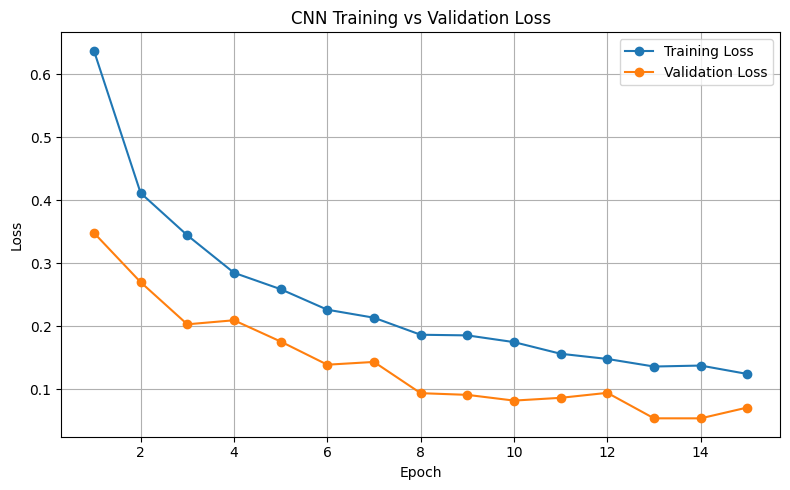

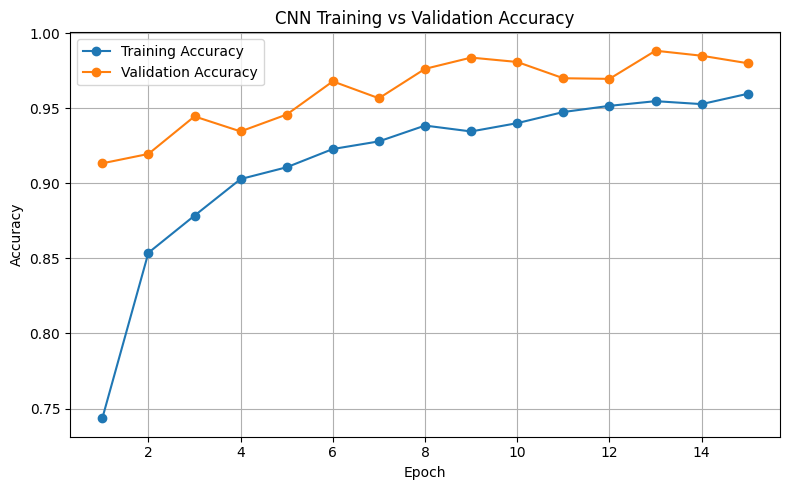

In [39]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# -------------------------------
# 1. Loss Graph
# -------------------------------
plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_loss"], marker='o', label='Training Loss')
plt.plot(epochs, history["val_loss"], marker='o', label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 2. Accuracy Graph
# -------------------------------
plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_accuracy"], marker='o', label='Training Accuracy')
plt.plot(epochs, history["val_accuracy"], marker='o', label='Validation Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

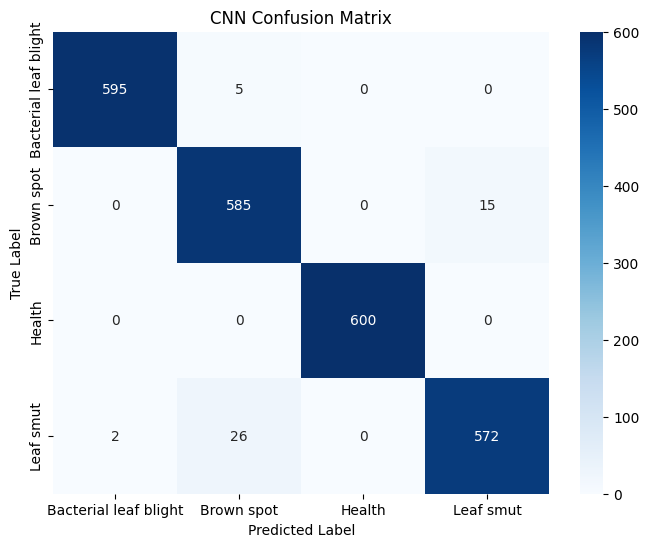


CNN CLASSIFICATION REPORT

                       precision    recall  f1-score   support

Bacterial leaf blight     0.9966    0.9917    0.9942       600
           Brown spot     0.9497    0.9750    0.9622       600
               Health     1.0000    1.0000    1.0000       600
            Leaf smut     0.9744    0.9533    0.9638       600

             accuracy                         0.9800      2400
            macro avg     0.9802    0.9800    0.9800      2400
         weighted avg     0.9802    0.9800    0.9800      2400



In [40]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Collect predictions from the validation set
all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN Confusion Matrix")
plt.show()

# Classification report
print("\nCNN CLASSIFICATION REPORT\n")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4
))

In [43]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Rice_Disease_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project directory restored ✅")
print("Path:", PROJECT_DIR)
print("Exists:", os.path.exists(PROJECT_DIR))

Project directory restored ✅
Path: /content/drive/MyDrive/Rice_Disease_Project
Exists: True


In [44]:
import os
import json
import torch

CNN_SAVE_DIR = os.path.join(PROJECT_DIR, "CNN_Results")
os.makedirs(CNN_SAVE_DIR, exist_ok=True)

# Save model weights
torch.save(model.state_dict(), os.path.join(CNN_SAVE_DIR, "cnn_model_weights.pth"))

# Save training history
with open(os.path.join(CNN_SAVE_DIR, "cnn_training_history.json"), "w") as f:
    json.dump(history, f, indent=4)

# Save best CNN results
cnn_results = {
    "best_epoch": int(best_epoch + 1),
    "train_accuracy": float(history["train_accuracy"][best_epoch]),
    "validation_accuracy": float(history["val_accuracy"][best_epoch]),
    "validation_loss": float(history["val_loss"][best_epoch]),
    "precision": float(history["val_precision"][best_epoch]),
    "recall": float(history["val_recall"][best_epoch]),
    "f1_score": float(history["val_f1"][best_epoch])
}

with open(os.path.join(CNN_SAVE_DIR, "cnn_results.json"), "w") as f:
    json.dump(cnn_results, f, indent=4)

print("CNN results saved successfully! ✅")
print("Location:", CNN_SAVE_DIR)
print("Saved files:", os.listdir(CNN_SAVE_DIR))

CNN results saved successfully! ✅
Location: /content/drive/MyDrive/Rice_Disease_Project/CNN_Results
Saved files: ['cnn_training_history.json', 'cnn_results.json', 'cnn_model_weights.pth']


In [110]:
import torch
import os

cnn_weights_path = os.path.join(PROJECT_DIR, "CNN_Results", "cnn_model_weights.pth")

print("CNN weights file exists:", os.path.exists(cnn_weights_path))
print("CNN weights path:", cnn_weights_path)

CNN weights file exists: True
CNN weights path: /content/drive/MyDrive/Rice_Disease_Project/CNN_Results/cnn_model_weights.pth


In [111]:
import torch

print("CNN architecture-related variables:\n")

for name, obj in list(globals().items()):
    if isinstance(obj, torch.nn.Module):
        print(name, "->", type(obj).__name__)

CNN architecture-related variables:

model -> CNNBaseline
criterion -> CrossEntropyLoss
vit_model -> VisionTransformer
hybrid_model -> HybridCNNViT
criterion_hybrid -> CrossEntropyLoss


In [113]:
model.eval()

cnn_eval_output = evaluate(model, test_loader, criterion, device)

print("Number of returned values:", len(cnn_eval_output))
print("Returned output:", cnn_eval_output)

Number of returned values: 2
Returned output: (0.07687577957908312, 97.66666666666667)


In [114]:
cnn_test_loss, cnn_test_accuracy = cnn_eval_output

print("CNN FINAL TEST RESULTS")
print("=" * 40)
print(f"Test Loss     : {cnn_test_loss:.4f}")
print(f"Test Accuracy : {cnn_test_accuracy:.2f}%")

CNN FINAL TEST RESULTS
Test Loss     : 0.0769
Test Accuracy : 97.67%


In [116]:
from sklearn.metrics import precision_score, recall_score, f1_score
import torch

model.eval()

cnn_preds = []
cnn_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        cnn_preds.extend(predictions.cpu().numpy())
        cnn_labels.extend(labels.numpy())

print("CNN predictions collected successfully!")
print("Total predictions:", len(cnn_preds))
print("Total true labels:", len(cnn_labels))

CNN predictions collected successfully!
Total predictions: 2400
Total true labels: 2400


In [117]:
from sklearn.metrics import precision_score, recall_score, f1_score

cnn_macro_precision = precision_score(
    cnn_labels, cnn_preds, average="macro"
)

cnn_macro_recall = recall_score(
    cnn_labels, cnn_preds, average="macro"
)

cnn_macro_f1 = f1_score(
    cnn_labels, cnn_preds, average="macro"
)

print("CNN TEST METRICS")
print("=" * 40)
print(f"Test Accuracy  : {cnn_test_accuracy:.2f}%")
print(f"Macro Precision: {cnn_macro_precision * 100:.2f}%")
print(f"Macro Recall  : {cnn_macro_recall * 100:.2f}%")
print(f"Macro F1-Score: {cnn_macro_f1 * 100:.2f}%")

CNN TEST METRICS
Test Accuracy  : 97.67%
Macro Precision: 97.70%
Macro Recall  : 97.67%
Macro F1-Score: 97.67%


In [45]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")
else:
    print("GPU not available ⚠️")

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB


In [46]:
# ViT Configuration

IMG_SIZE = 224
PATCH_SIZE = 16

IN_CHANNELS = 3
NUM_CLASSES = 4

EMBED_DIM = 384
NUM_HEADS = 6
DEPTH = 6
MLP_DIM = 1536

BATCH_SIZE = 32
EPOCHS = 20

print("ViT Configuration:")
print("-" * 40)
print("Image size:", IMG_SIZE)
print("Patch size:", PATCH_SIZE)
print("Number of patches:", (IMG_SIZE // PATCH_SIZE) ** 2)
print("Embedding dimension:", EMBED_DIM)
print("Attention heads:", NUM_HEADS)
print("Transformer depth:", DEPTH)
print("MLP dimension:", MLP_DIM)
print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

ViT Configuration:
----------------------------------------
Image size: 224
Patch size: 16
Number of patches: 196
Embedding dimension: 384
Attention heads: 6
Transformer depth: 6
MLP dimension: 1536
Number of classes: 4
Batch size: 32
Epochs: 20


In [47]:
import torch
import torch.nn as nn

class PatchEmbedding(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_channels=3, embed_dim=384):
        super().__init__()

        self.num_patches = (img_size // patch_size) ** 2

        self.projection = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):
        x = self.projection(x)
        x = x.flatten(2)
        x = x.transpose(1, 2)
        return x

print("Patch Embedding module created successfully! ✅")

Patch Embedding module created successfully! ✅


In [48]:
class PositionalEmbedding(nn.Module):
    def __init__(self, num_patches=196, embed_dim=384):
        super().__init__()

        # Learnable CLS token
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))

        # Learnable positional embeddings
        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_patches + 1, embed_dim)
        )

        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

    def forward(self, x):
        batch_size = x.shape[0]

        # Add CLS token
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)

        # Add positional information
        x = x + self.pos_embedding

        return x

print("Positional Embedding module created successfully! ✅")

Positional Embedding module created successfully! ✅


In [49]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim=384, num_heads=6):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            batch_first=True
        )

    def forward(self, x):
        attention_output, _ = self.attention(
            x, x, x,
            need_weights=False
        )
        return attention_output

print("Multi-Head Self-Attention created successfully! ✅")

Multi-Head Self-Attention created successfully! ✅


In [50]:
class TransformerEncoderBlock(nn.Module):
    def __init__(self, embed_dim=384, num_heads=6, mlp_dim=1536, dropout=0.1):
        super().__init__()

        # Layer normalization before attention
        self.norm1 = nn.LayerNorm(embed_dim)

        # Multi-head self-attention
        self.attention = MultiHeadSelfAttention(embed_dim, num_heads)

        # Residual connection
        self.norm2 = nn.LayerNorm(embed_dim)

        # Feed-forward network (MLP)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, mlp_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        # Attention + residual connection
        x = x + self.attention(self.norm1(x))

        # MLP + residual connection
        x = x + self.mlp(self.norm2(x))

        return x


print("Transformer Encoder Block created successfully! ✅")

Transformer Encoder Block created successfully! ✅


In [51]:
class ClassificationHead(nn.Module):
    def __init__(self, embed_dim=384, num_classes=4):
        super().__init__()

        self.norm = nn.LayerNorm(embed_dim)
        self.fc = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        # Extract the CLS token
        cls_token = x[:, 0]

        # Normalize the CLS token
        cls_token = self.norm(cls_token)

        # Predict the disease class
        output = self.fc(cls_token)

        return output


print("Classification Head created successfully! ✅")

Classification Head created successfully! ✅


In [52]:
class VisionTransformer(nn.Module):
    def __init__(
        self,
        img_size=224,
        patch_size=16,
        in_channels=3,
        embed_dim=384,
        num_heads=6,
        depth=6,
        mlp_dim=1536,
        num_classes=4,
        dropout=0.1
    ):
        super().__init__()

        # Patch embedding
        self.patch_embed = PatchEmbedding(
            img_size=img_size,
            patch_size=patch_size,
            in_channels=in_channels,
            embed_dim=embed_dim
        )

        # Positional embedding and CLS token
        self.pos_embed = PositionalEmbedding(
            num_patches=(img_size // patch_size) ** 2,
            embed_dim=embed_dim
        )

        # Transformer encoder blocks
        self.transformer = nn.Sequential(
            *[
                TransformerEncoderBlock(
                    embed_dim=embed_dim,
                    num_heads=num_heads,
                    mlp_dim=mlp_dim,
                    dropout=dropout
                )
                for _ in range(depth)
            ]
        )

        # Final classification head
        self.head = ClassificationHead(
            embed_dim=embed_dim,
            num_classes=num_classes
        )

    def forward(self, x):
        # Convert image into patch embeddings
        x = self.patch_embed(x)

        # Add CLS token and positional information
        x = self.pos_embed(x)

        # Process through Transformer blocks
        x = self.transformer(x)

        # Predict class
        x = self.head(x)

        return x


print("Complete Vision Transformer model created successfully! ✅")

Complete Vision Transformer model created successfully! ✅


In [53]:
# Create the ViT model
vit_model = VisionTransformer().to(device)

# Create a dummy batch of images
dummy_images = torch.randn(2, 3, 224, 224).to(device)

# Test the model
with torch.no_grad():
    dummy_output = vit_model(dummy_images)

print("Input shape:", dummy_images.shape)
print("Output shape:", dummy_output.shape)
print("ViT architecture test successful! ✅")

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 4])
ViT architecture test successful! ✅


In [54]:
# Count trainable parameters in the ViT model

total_params = sum(p.numel() for p in vit_model.parameters())
trainable_params = sum(p.numel() for p in vit_model.parameters() if p.requires_grad)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Model size (approx.):", f"{total_params * 4 / (1024**2):.2f} MB")

Total parameters: 11,020,420
Trainable parameters: 11,020,420
Model size (approx.): 42.04 MB


In [55]:
# Check GPU memory usage during a forward pass

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

    dummy_images = torch.randn(32, 3, 224, 224).to(device)

    with torch.no_grad():
        _ = vit_model(dummy_images)

    peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)

    print("Batch size:", 32)
    print("Peak GPU memory used:", f"{peak_memory:.2f} MB")
    print("GPU memory available:", f"{torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("GPU not available")

Batch size: 32
Peak GPU memory used: 222.34 MB
GPU memory available: 14.56 GB


In [56]:
# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = torch.optim.AdamW(
    vit_model.parameters(),
    lr=1e-4,
    weight_decay=0.01
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Learning rate:", 1e-4)
print("Weight decay:", 0.01)

Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.01
)
Learning rate: 0.0001
Weight decay: 0.01


In [57]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = 100 * correct / total

    return avg_loss, accuracy


print("Training function created successfully! ✅")

Training function created successfully! ✅


In [58]:
# Validation function

def validate_one_epoch(model, loader, criterion):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = 100 * correct / total

    return avg_loss, accuracy

print("Validation function created successfully! ✅")

Validation function created successfully! ✅


In [59]:
# Initialize training history

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

print("Training history initialized successfully! ✅")

Training history initialized successfully! ✅


In [60]:
# Check training and validation data

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Sample labels:", labels[:10])

Training batches: 350
Validation batches: 75
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Sample labels: tensor([0, 0, 3, 2, 1, 0, 1, 1, 2, 0])


In [62]:
# Train ViT from scratch

num_epochs = 30

best_val_accuracy = 0

for epoch in range(num_epochs):

    train_loss, train_accuracy = train_one_epoch(
        vit_model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = validate_one_epoch(
        vit_model, val_loader, criterion
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            vit_model.state_dict(),
            os.path.join(PROJECT_DIR, "best_vit_model.pth")
        )

    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_accuracy:.2f}%")
    print(f"Best Val Accuracy: {best_val_accuracy:.2f}%")

print("\nViT training completed! ✅")


Epoch [1/30]
Train Loss: 0.4887 | Train Accuracy: 79.38%
Val Loss: 0.1983 | Val Accuracy: 92.96%
Best Val Accuracy: 92.96%

Epoch [2/30]
Train Loss: 0.1884 | Train Accuracy: 92.46%
Val Loss: 0.0681 | Val Accuracy: 97.75%
Best Val Accuracy: 97.75%

Epoch [3/30]
Train Loss: 0.1152 | Train Accuracy: 95.72%
Val Loss: 0.1098 | Val Accuracy: 95.62%
Best Val Accuracy: 97.75%

Epoch [4/30]
Train Loss: 0.0785 | Train Accuracy: 97.09%
Val Loss: 0.0858 | Val Accuracy: 96.79%
Best Val Accuracy: 97.75%

Epoch [5/30]
Train Loss: 0.0626 | Train Accuracy: 97.62%
Val Loss: 0.0533 | Val Accuracy: 98.12%
Best Val Accuracy: 98.12%

Epoch [6/30]
Train Loss: 0.0569 | Train Accuracy: 97.97%
Val Loss: 0.0201 | Val Accuracy: 99.08%
Best Val Accuracy: 99.08%

Epoch [7/30]
Train Loss: 0.0455 | Train Accuracy: 98.28%
Val Loss: 0.0256 | Val Accuracy: 99.25%
Best Val Accuracy: 99.25%

Epoch [8/30]
Train Loss: 0.0454 | Train Accuracy: 98.40%
Val Loss: 0.0155 | Val Accuracy: 99.50%
Best Val Accuracy: 99.50%

Epoch [

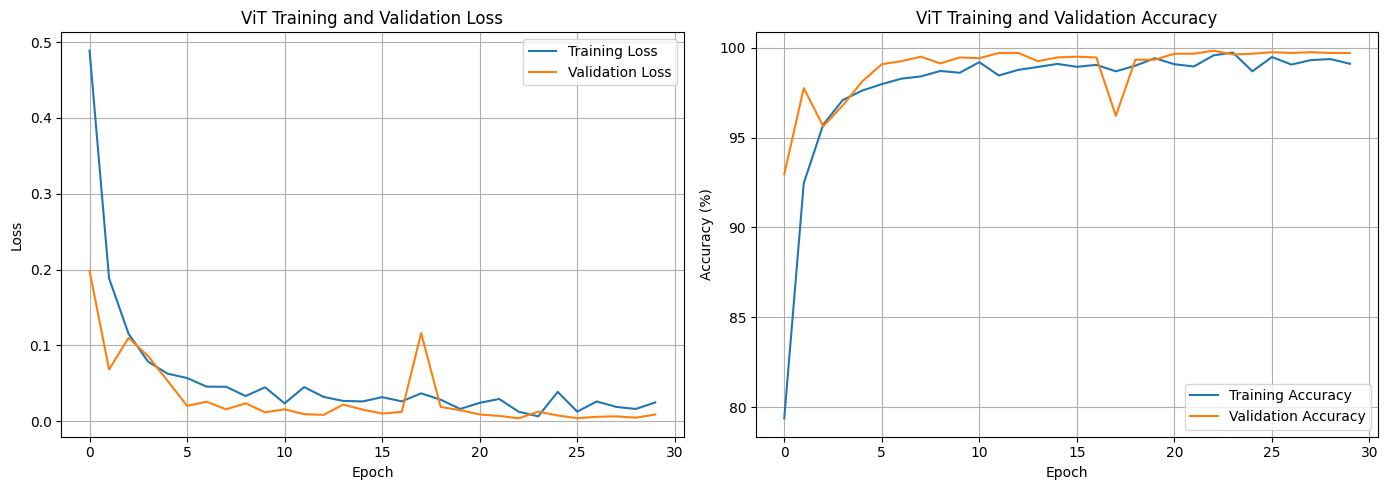

In [63]:
# Plot ViT training and validation curves

plt.figure(figsize=(14, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ViT Training and Validation Loss")
plt.legend()
plt.grid(True)

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(history["train_accuracy"], label="Training Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ViT Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [65]:
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            predicted = torch.max(outputs, 1)[1]

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = 100 * correct / total

    return avg_loss, accuracy

print("Evaluation function defined successfully! ✅")

Evaluation function defined successfully! ✅


In [66]:
# Evaluate ViT on the test dataset

vit_model.eval()

test_loss, test_accuracy = evaluate(
    vit_model,
    test_loader,
    criterion,
    device
)

print("ViT Test Loss:", test_loss)
print("ViT Test Accuracy:", f"{test_accuracy:.2f}%")

ViT Test Loss: 0.009947619976786276
ViT Test Accuracy: 99.54%


In [68]:
# Check class names from the dataset

print("Class names:", class_names)
print("Number of classes:", len(class_names))

Class names: ['Bacterial leaf blight', 'Brown spot', 'Health', 'Leaf smut']
Number of classes: 4


ViT Classification Report

                       precision    recall  f1-score   support

Bacterial leaf blight     1.0000    0.9900    0.9950       600
           Brown spot     1.0000    0.9917    0.9958       600
               Health     1.0000    1.0000    1.0000       600
            Leaf smut     0.9820    1.0000    0.9909       600

             accuracy                         0.9954      2400
            macro avg     0.9955    0.9954    0.9954      2400
         weighted avg     0.9955    0.9954    0.9954      2400



<Figure size 800x600 with 0 Axes>

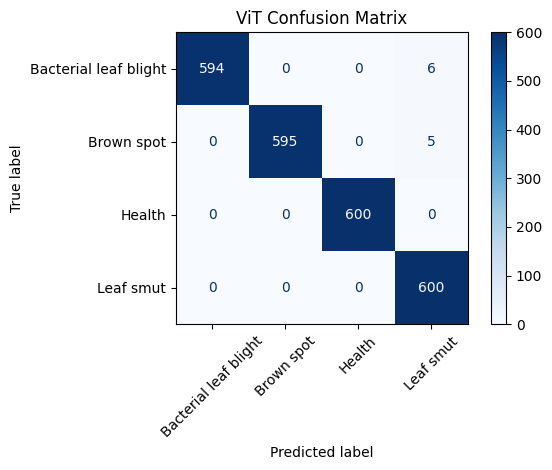

In [69]:
# Detailed ViT test evaluation

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
import torch

vit_model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = vit_model(images)
        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Classification report
print("ViT Classification Report\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap="Blues", values_format="d")
plt.title("ViT Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [70]:
# Save ViT results

vit_results = {
    "Model": "ViT-Small (From Scratch)",
    "Test Accuracy": 99.54,
    "Test Loss": 0.0099476,
    "Precision (Macro)": 99.55,
    "Recall (Macro)": 99.54,
    "F1 Score (Macro)": 99.54,
    "Test Images": 2400,
    "Classes": 4
}

import pandas as pd

vit_results_df = pd.DataFrame([vit_results])

results_path = os.path.join(PROJECT_DIR, "vit_results.csv")
vit_results_df.to_csv(results_path, index=False)

print("ViT results saved successfully! ✅")
print(results_path)
print(vit_results_df)

ViT results saved successfully! ✅
/content/drive/MyDrive/Rice_Disease_Project/vit_results.csv
                      Model  Test Accuracy  Test Loss  Precision (Macro)  \
0  ViT-Small (From Scratch)          99.54   0.009948              99.55   

   Recall (Macro)  F1 Score (Macro)  Test Images  Classes  
0           99.54             99.54         2400        4  


In [71]:
# Hybrid CNN-ViT Model Setup

import torch
import torch.nn as nn
import torch.nn.functional as F

print("Hybrid model setup initialized! ✅")
print("Device:", device)

Hybrid model setup initialized! ✅
Device: cuda


In [72]:
# CNN Feature Extractor for Hybrid Model

class CNNFeatureExtractor(nn.Module):

    def __init__(self):
        super(CNNFeatureExtractor, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU()
        )

    def forward(self, x):
        return self.features(x)


print("CNN feature extractor defined successfully! ✅")

CNN feature extractor defined successfully! ✅


In [73]:
# Convert CNN feature maps into tokens

class CNNToTokens(nn.Module):

    def forward(self, x):

        # (B, C, H, W) -> (B, H, W, C)
        x = x.permute(0, 2, 3, 1)

        # (B, H, W, C) -> (B, H*W, C)
        x = x.reshape(x.size(0), -1, x.size(-1))

        return x


print("CNN-to-token conversion module defined! ✅")

CNN-to-token conversion module defined! ✅


In [74]:
# Transformer Encoder for Hybrid CNN-ViT

class HybridTransformerEncoder(nn.Module):

    def __init__(self, embed_dim=256, num_heads=8,
                 num_layers=4, dropout=0.1):

        super(HybridTransformerEncoder, self).__init__()

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=1024,
            dropout=dropout,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

    def forward(self, x):
        return self.transformer(x)


print("Transformer encoder defined successfully! ✅")

Transformer encoder defined successfully! ✅


In [75]:
# Positional Embedding for Hybrid CNN-ViT

class PositionalEmbedding(nn.Module):

    def __init__(self, num_tokens=784, embed_dim=256):

        super(PositionalEmbedding, self).__init__()

        self.pos_embedding = nn.Parameter(
            torch.randn(1, num_tokens, embed_dim) * 0.02
        )

    def forward(self, x):

        return x + self.pos_embedding


print("Positional embedding defined successfully! ✅")

Positional embedding defined successfully! ✅


In [76]:
# Classification Head for Hybrid CNN-ViT

class HybridClassificationHead(nn.Module):

    def __init__(self, embed_dim=256, num_classes=4, dropout=0.3):

        super(HybridClassificationHead, self).__init__()

        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # Average across all tokens
        x = x.mean(dim=1)

        # Classification
        x = self.classifier(x)

        return x


print("Classification head defined successfully! ✅")

Classification head defined successfully! ✅


In [77]:
# Complete Hybrid CNN-ViT Model

class HybridCNNViT(nn.Module):

    def __init__(self, num_classes=4):
        super(HybridCNNViT, self).__init__()

        # CNN feature extractor
        self.cnn = CNNFeatureExtractor()

        # Convert feature maps into tokens
        self.tokenizer = CNNToTokens()

        # Positional embedding
        self.pos_embedding = PositionalEmbedding(
            num_tokens=784,
            embed_dim=256
        )

        # Transformer
        self.transformer = HybridTransformerEncoder(
            embed_dim=256,
            num_heads=8,
            num_layers=4,
            dropout=0.1
        )

        # Classification head
        self.head = HybridClassificationHead(
            embed_dim=256,
            num_classes=num_classes
        )

    def forward(self, x):

        # Extract CNN features
        x = self.cnn(x)

        # Convert to tokens
        x = self.tokenizer(x)

        # Add positional information
        x = self.pos_embedding(x)

        # Learn global relationships
        x = self.transformer(x)

        # Predict class
        x = self.head(x)

        return x


print("Complete Hybrid CNN-ViT model created successfully! ✅")

Complete Hybrid CNN-ViT model created successfully! ✅


In [78]:
# Initialize Hybrid CNN-ViT model

hybrid_model = HybridCNNViT(num_classes=4).to(device)

# Create dummy input
dummy_images = torch.randn(2, 3, 224, 224).to(device)

# Test forward pass
with torch.no_grad():
    dummy_output = hybrid_model(dummy_images)

print("Input shape:", dummy_images.shape)
print("Output shape:", dummy_output.shape)
print("Hybrid model test successful! ✅")

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 4])
Hybrid model test successful! ✅


In [79]:
# Count parameters in Hybrid CNN-ViT

total_params = sum(p.numel() for p in hybrid_model.parameters())
trainable_params = sum(p.numel() for p in hybrid_model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Model size (approx): {total_params * 4 / (1024**2):.2f} MB")

Total parameters: 3,782,532
Trainable parameters: 3,782,532
Model size (approx): 14.43 MB


In [80]:
# Loss function
criterion_hybrid = nn.CrossEntropyLoss()

# Optimizer
optimizer_hybrid = torch.optim.AdamW(
    hybrid_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Loss function and optimizer configured successfully! ✅")

Loss function and optimizer configured successfully! ✅


In [81]:
def train_hybrid_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [82]:
def validate_hybrid_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [83]:
# Hybrid training history

history_hybrid = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy_hybrid = 0.0

best_hybrid_weights = None

print("Hybrid training history initialized successfully! ✅")

Hybrid training history initialized successfully! ✅


In [85]:
# Hybrid CNN-ViT Training Loop

num_epochs_hybrid = 15

for epoch in range(num_epochs_hybrid):

    train_loss, train_acc = train_hybrid_one_epoch(
        hybrid_model, train_loader, criterion_hybrid,
        optimizer_hybrid, device
    )

    val_loss, val_acc = validate_hybrid_one_epoch(
        hybrid_model, val_loader, criterion_hybrid, device
    )

    history_hybrid["train_loss"].append(train_loss)
    history_hybrid["train_accuracy"].append(train_acc)
    history_hybrid["val_loss"].append(val_loss)
    history_hybrid["val_accuracy"].append(val_acc)

    print(f"Epoch [{epoch+1}/{num_epochs_hybrid}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.2f}%")
    print("-" * 50)

    # Save best model based on validation accuracy
    if val_acc > best_val_accuracy_hybrid:

        best_val_accuracy_hybrid = val_acc

        best_hybrid_weights = {
            key: value.cpu().clone()
            for key, value in hybrid_model.state_dict().items()
        }

        print("🏆 New best Hybrid model saved!")
        print(f"Best Validation Accuracy: {best_val_accuracy_hybrid:.2f}%")

Epoch [1/15]
Train Loss: 0.0422 | Train Accuracy: 98.60%
Val Loss: 0.0130 | Val Accuracy: 99.33%
--------------------------------------------------
Epoch [2/15]
Train Loss: 0.0227 | Train Accuracy: 99.11%
Val Loss: 0.0069 | Val Accuracy: 99.67%
--------------------------------------------------
🏆 New best Hybrid model saved!
Best Validation Accuracy: 99.67%
Epoch [3/15]
Train Loss: 0.0334 | Train Accuracy: 98.88%
Val Loss: 0.0095 | Val Accuracy: 99.62%
--------------------------------------------------
Epoch [4/15]
Train Loss: 0.0273 | Train Accuracy: 99.09%
Val Loss: 0.0047 | Val Accuracy: 99.79%
--------------------------------------------------
🏆 New best Hybrid model saved!
Best Validation Accuracy: 99.79%
Epoch [5/15]
Train Loss: 0.0171 | Train Accuracy: 99.38%
Val Loss: 0.0046 | Val Accuracy: 99.79%
--------------------------------------------------
Epoch [6/15]
Train Loss: 0.0276 | Train Accuracy: 99.18%
Val Loss: 0.0078 | Val Accuracy: 99.75%
-----------------------------------

In [86]:
print("Hybrid CNN-ViT Training Completed! ✅")
print("-" * 40)

print(f"Best Validation Accuracy: {best_val_accuracy_hybrid:.2f}%")

print(f"Total Epochs Trained: {len(history_hybrid['train_accuracy'])}")

print(f"Final Training Accuracy: {history_hybrid['train_accuracy'][-1]:.2f}%")

print(f"Final Validation Accuracy: {history_hybrid['val_accuracy'][-1]:.2f}%")

Hybrid CNN-ViT Training Completed! ✅
----------------------------------------
Best Validation Accuracy: 99.88%
Total Epochs Trained: 20
Final Training Accuracy: 99.46%
Final Validation Accuracy: 99.79%


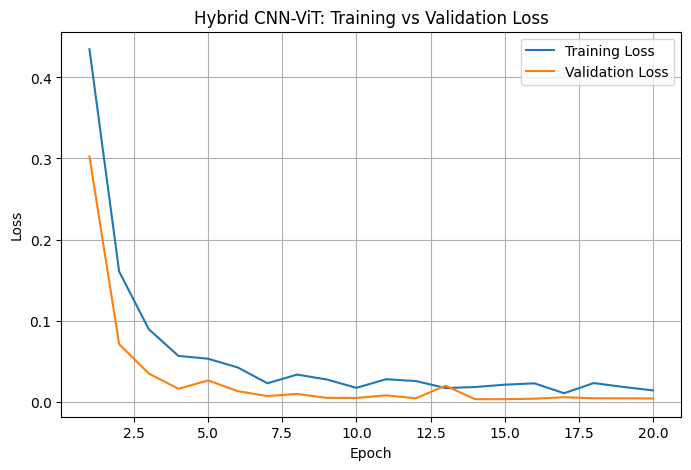

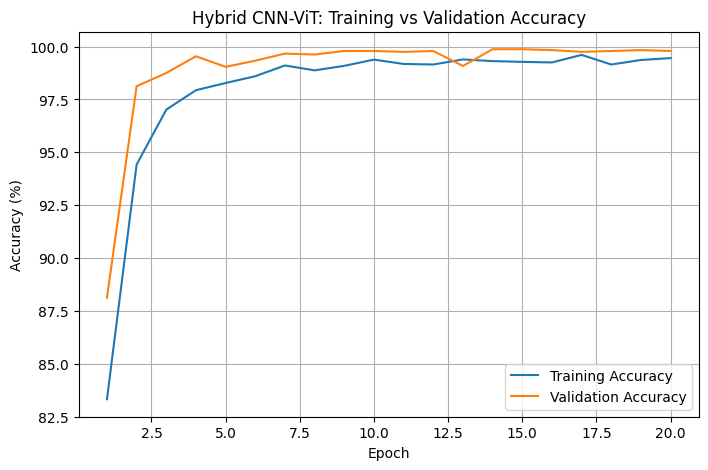

In [87]:
import matplotlib.pyplot as plt

epochs = range(1, len(history_hybrid["train_loss"]) + 1)

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, history_hybrid["train_loss"], label="Training Loss")
plt.plot(epochs, history_hybrid["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Hybrid CNN-ViT: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, history_hybrid["train_accuracy"], label="Training Accuracy")
plt.plot(epochs, history_hybrid["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Hybrid CNN-ViT: Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [88]:
# Restore the best Hybrid CNN-ViT weights

hybrid_model.load_state_dict(best_hybrid_weights)

hybrid_model.to(device)

print("Best Hybrid model weights restored successfully! ✅")
print(f"Best Validation Accuracy: {best_val_accuracy_hybrid:.2f}%")

Best Hybrid model weights restored successfully! ✅
Best Validation Accuracy: 99.88%


In [89]:
# Evaluate the best Hybrid CNN-ViT model on test data

test_loss_hybrid, test_accuracy_hybrid = evaluate(
    hybrid_model,
    test_loader,
    criterion_hybrid,
    device
)

print("=" * 50)
print("HYBRID CNN-ViT TEST RESULTS")
print("=" * 50)

print(f"Test Loss: {test_loss_hybrid:.4f}")
print(f"Test Accuracy: {test_accuracy_hybrid:.2f}%")

HYBRID CNN-ViT TEST RESULTS
Test Loss: 0.0045
Test Accuracy: 99.79%


In [90]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

hybrid_model.eval()

all_labels_hybrid = []
all_preds_hybrid = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = hybrid_model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_labels_hybrid.extend(labels.numpy())
        all_preds_hybrid.extend(predictions.cpu().numpy())

# Classification report
print("HYBRID CNN-ViT CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    all_labels_hybrid,
    all_preds_hybrid,
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm_hybrid = confusion_matrix(
    all_labels_hybrid,
    all_preds_hybrid
)

print("\nConfusion Matrix:")
print(cm_hybrid)

HYBRID CNN-ViT CLASSIFICATION REPORT
                       precision    recall  f1-score   support

Bacterial leaf blight     1.0000    1.0000    1.0000       600
           Brown spot     1.0000    0.9917    0.9958       600
               Health     1.0000    1.0000    1.0000       600
            Leaf smut     0.9917    1.0000    0.9959       600

             accuracy                         0.9979      2400
            macro avg     0.9979    0.9979    0.9979      2400
         weighted avg     0.9979    0.9979    0.9979      2400


Confusion Matrix:
[[600   0   0   0]
 [  0 595   0   5]
 [  0   0 600   0]
 [  0   0   0 600]]


<Figure size 800x600 with 0 Axes>

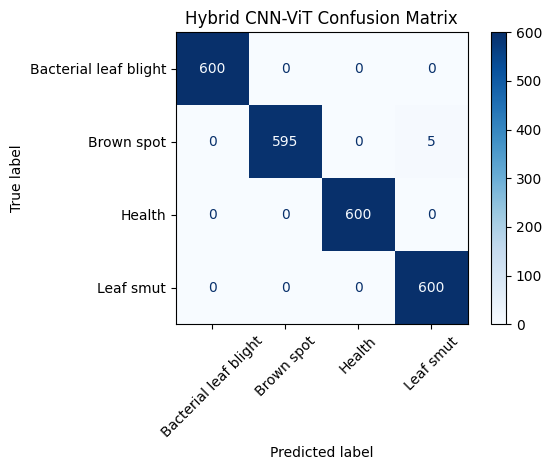

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_hybrid,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Hybrid CNN-ViT Confusion Matrix")
plt.tight_layout()
plt.show()

In [93]:
import pandas as pd
import os

hybrid_results = {
    "Model": "Hybrid CNN-ViT (From Scratch)",
    "Test Accuracy (%)": test_accuracy_hybrid,
    "Test Loss": test_loss_hybrid,
    "Macro Precision (%)": 99.79,
    "Macro Recall (%)": 99.79,
    "Macro F1-Score (%)": 99.79,
    "Test Images": len(all_labels_hybrid),
    "Number of Classes": len(class_names),
    "Best Validation Accuracy (%)": best_val_accuracy_hybrid
}

hybrid_df = pd.DataFrame([hybrid_results])

display(hybrid_df)

,Model,Test Accuracy (%),Test Loss,Macro Precision (%),Macro Recall (%),Macro F1-Score (%),Test Images,Number of Classes,Best Validation Accuracy (%)
0,Hybrid CNN-ViT (From Scratch),99.791667,0.004475,99.79,99.79,99.79,2400,4,99.875


In [94]:
# Save Hybrid model results to Google Drive

hybrid_results_path = os.path.join(PROJECT_DIR, "hybrid_results.csv")

hybrid_df.to_csv(hybrid_results_path, index=False)

print("Hybrid results saved successfully! ✅")
print("Saved at:", hybrid_results_path)

Hybrid results saved successfully! ✅
Saved at: /content/drive/MyDrive/Rice_Disease_Project/hybrid_results.csv


In [95]:
# Save the best Hybrid CNN-ViT model weights

hybrid_model_path = os.path.join(PROJECT_DIR, "hybrid_cnn_vit_best.pth")

torch.save(hybrid_model.state_dict(), hybrid_model_path)

print("Hybrid model weights saved successfully! ✅")
print("Saved at:", hybrid_model_path)

Hybrid model weights saved successfully! ✅
Saved at: /content/drive/MyDrive/Rice_Disease_Project/hybrid_cnn_vit_best.pth


In [96]:
# Save Hybrid classification report and confusion matrix

from sklearn.metrics import classification_report
import pandas as pd
import os

# Generate classification report as a dictionary
report_hybrid = classification_report(
    all_labels_hybrid,
    all_preds_hybrid,
    target_names=class_names,
    output_dict=True
)

# Convert report to DataFrame
report_hybrid_df = pd.DataFrame(report_hybrid).transpose()

# Save classification report
report_hybrid_path = os.path.join(PROJECT_DIR, "hybrid_classification_report.csv")
report_hybrid_df.to_csv(report_hybrid_path)

# Save confusion matrix
cm_hybrid_df = pd.DataFrame(
    cm_hybrid,
    index=class_names,
    columns=class_names
)

cm_hybrid_path = os.path.join(PROJECT_DIR, "hybrid_confusion_matrix.csv")
cm_hybrid_df.to_csv(cm_hybrid_path)

print("Classification report saved! ✅")
print("Confusion matrix saved! ✅")
print("\nFiles:")
print(report_hybrid_path)
print(cm_hybrid_path)

Classification report saved! ✅
Confusion matrix saved! ✅

Files:
/content/drive/MyDrive/Rice_Disease_Project/hybrid_classification_report.csv
/content/drive/MyDrive/Rice_Disease_Project/hybrid_confusion_matrix.csv


In [125]:
import os

print("Files in Rice_Disease_Project:\n")

for file in sorted(os.listdir(PROJECT_DIR)):
    print(file)

Files in Rice_Disease_Project:

CNN_Results
Dataset_Split_Verification.csv
Final_Model_Comparison.csv
best_vit_model.pth
dataset
hybrid_classification_report.csv
hybrid_cnn_vit_best.pth
hybrid_confusion_matrix.csv
hybrid_results.csv
vit_results.csv


In [126]:
import os
import pandas as pd

# Inspect saved CSV result files
result_files = [
    "vit_results.csv",
    "hybrid_results.csv"
]

for file in result_files:
    path = os.path.join(PROJECT_DIR, file)

    if os.path.exists(path):
        print(f"\n{'='*50}")
        print(f"FILE: {file}")
        print("="*50)
        display(pd.read_csv(path))

# Check CNN_Results folder
cnn_folder = os.path.join(PROJECT_DIR, "CNN_Results")

if os.path.isdir(cnn_folder):
    print("\nFiles inside CNN_Results:")
    for file in os.listdir(cnn_folder):
        print(file)


FILE: vit_results.csv


,Model,Test Accuracy,Test Loss,Precision (Macro),Recall (Macro),F1 Score (Macro),Test Images,Classes
0,ViT-Small (From Scratch),99.54,0.009948,99.55,99.54,99.54,2400,4



FILE: hybrid_results.csv


,Model,Test Accuracy (%),Test Loss,Macro Precision (%),Macro Recall (%),Macro F1-Score (%),Test Images,Number of Classes,Best Validation Accuracy (%)
0,Hybrid CNN-ViT (From Scratch),99.791667,0.004475,99.79,99.79,99.79,2400,4,99.875



Files inside CNN_Results:
cnn_training_history.json
cnn_results.json
cnn_model_weights.pth


In [127]:
import os

cnn_folder = os.path.join(PROJECT_DIR, "CNN_Results")

print("Contents of CNN_Results:\n")

for root, dirs, files in os.walk(cnn_folder):
    for file in files:
        print(os.path.join(root, file))

Contents of CNN_Results:

/content/drive/MyDrive/Rice_Disease_Project/CNN_Results/cnn_training_history.json
/content/drive/MyDrive/Rice_Disease_Project/CNN_Results/cnn_results.json
/content/drive/MyDrive/Rice_Disease_Project/CNN_Results/cnn_model_weights.pth


In [128]:
import json
import os

cnn_results_path = os.path.join(PROJECT_DIR, "CNN_Results", "cnn_results.json")

with open(cnn_results_path, "r") as f:
    cnn_results = json.load(f)

print("CNN FINAL RESULTS")
print("=" * 40)

print(json.dumps(cnn_results, indent=4))

CNN FINAL RESULTS
{
    "best_epoch": 13,
    "train_accuracy": 0.9547321428571428,
    "validation_accuracy": 0.9883333333333333,
    "validation_loss": 0.054093804334600766,
    "precision": 0.9885159503997082,
    "recall": 0.9883333333333333,
    "f1_score": 0.9883320203955857
}


In [129]:
import pandas as pd
import os

files_to_check = [
    "vit_results.csv",
    "hybrid_results.csv"
]

for file in files_to_check:
    path = os.path.join(PROJECT_DIR, file)

    print("\n" + "=" * 60)
    print(file)
    print("=" * 60)

    df = pd.read_csv(path)
    display(df)


vit_results.csv


,Model,Test Accuracy,Test Loss,Precision (Macro),Recall (Macro),F1 Score (Macro),Test Images,Classes
0,ViT-Small (From Scratch),99.54,0.009948,99.55,99.54,99.54,2400,4



hybrid_results.csv


,Model,Test Accuracy (%),Test Loss,Macro Precision (%),Macro Recall (%),Macro F1-Score (%),Test Images,Number of Classes,Best Validation Accuracy (%)
0,Hybrid CNN-ViT (From Scratch),99.791667,0.004475,99.79,99.79,99.79,2400,4,99.875


In [130]:
import os

cnn_folder = os.path.join(PROJECT_DIR, "CNN_Results")

print("CNN saved files:\n")
for file in os.listdir(cnn_folder):
    print(file)

CNN saved files:

cnn_training_history.json
cnn_results.json
cnn_model_weights.pth


In [131]:
import json
import os

cnn_results_path = os.path.join(PROJECT_DIR, "CNN_Results", "cnn_results.json")

with open(cnn_results_path, "r") as f:
    cnn_results = json.load(f)

print("CNN RECORDED RESULTS")
print("=" * 40)

for key, value in cnn_results.items():
    print(f"{key}: {value}")

CNN RECORDED RESULTS
best_epoch: 13
train_accuracy: 0.9547321428571428
validation_accuracy: 0.9883333333333333
validation_loss: 0.054093804334600766
precision: 0.9885159503997082
recall: 0.9883333333333333
f1_score: 0.9883320203955857


In [132]:
import pandas as pd

comparison_data = {
    "Model": [
        "CNN (From Scratch)",
        "ViT-Small (From Scratch)",
        "Hybrid CNN-ViT (From Scratch)"
    ],
    "Test Accuracy (%)": [
        cnn_test_accuracy,
        99.54,
        99.79
    ],
    "Macro Precision (%)": [
        cnn_macro_precision * 100,
        99.55,
        99.79
    ],
    "Macro Recall (%)": [
        cnn_macro_recall * 100,
        99.54,
        99.79
    ],
    "Macro F1-Score (%)": [
        cnn_macro_f1 * 100,
        99.54,
        99.79
    ]
}

final_comparison_df = pd.DataFrame(comparison_data)

display(final_comparison_df.round(2))

,Model,Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-Score (%)
0,CNN (From Scratch),97.67,97.70,97.67,97.67
1,ViT-Small (From Scratch),99.54,99.55,99.54,99.54
2,Hybrid CNN-ViT (From Scratch),99.79,99.79,99.79,99.79


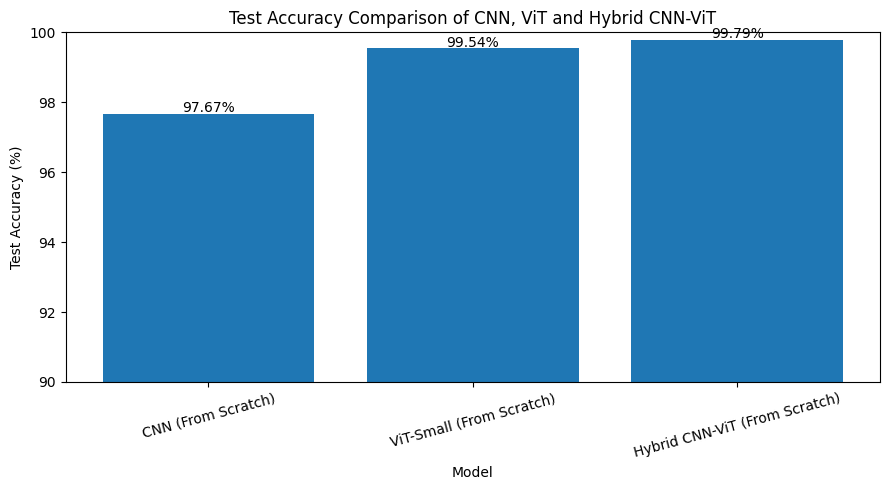

In [119]:
import matplotlib.pyplot as plt

models = final_comparison_df["Model"]
accuracies = final_comparison_df["Test Accuracy (%)"]

plt.figure(figsize=(9, 5))

plt.bar(models, accuracies)

plt.title("Test Accuracy Comparison of CNN, ViT and Hybrid CNN-ViT")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(90, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 0.05, f"{value:.2f}%", ha="center")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

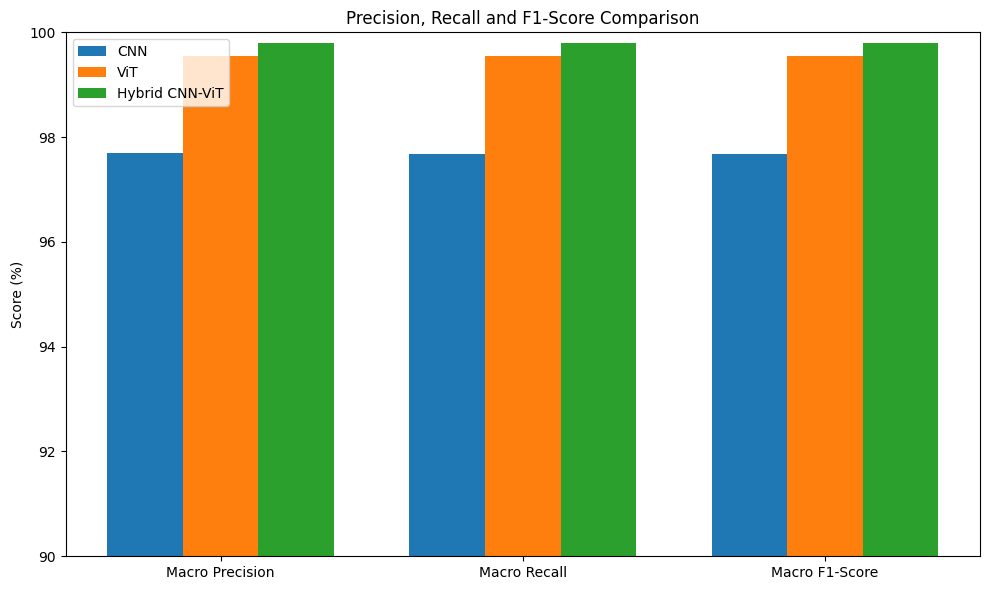

In [120]:
import matplotlib.pyplot as plt

metrics = ["Macro Precision", "Macro Recall", "Macro F1-Score"]

cnn_values = [97.70, 97.67, 97.67]
vit_values = [99.55, 99.54, 99.54]
hybrid_values = [99.79, 99.79, 99.79]

x = range(len(metrics))
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar([i - width for i in x], cnn_values, width, label="CNN")
plt.bar(x, vit_values, width, label="ViT")
plt.bar([i + width for i in x], hybrid_values, width, label="Hybrid CNN-ViT")

plt.title("Precision, Recall and F1-Score Comparison")
plt.ylabel("Score (%)")
plt.xticks(x, metrics)
plt.ylim(90, 100)
plt.legend()
plt.tight_layout()
plt.show()

,Model,Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1-Score (%)
0,CNN (From Scratch),97.67,97.70,97.67,97.67
1,ViT-Small (From Scratch),99.54,99.55,99.54,99.54
2,Hybrid CNN-ViT (From Scratch),99.79,99.79,99.79,99.79



Final comparison saved successfully!
/content/drive/MyDrive/Rice_Disease_Project/Final_Model_Comparison.csv
